In [2]:
# Cell 1: connect Colab to Google Drive and move into our project folder
from google.colab import drive
drive.mount('/content/drive')

import os, sys
ROOT = '/content/drive/MyDrive/ml_mini_project/ML-Bike-Rental-Demand-Forecasting'
os.chdir(ROOT)            # behave as if we're in the project root, like in VS Code
sys.path.insert(0, ROOT)  # lets Python find our own folders: preprocessing/, modeling/
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/ml_mini_project/ML-Bike-Rental-Demand-Forecasting


In [3]:
# Cell 2: install the two libraries Colab doesn't ship with, then check our files are there
!pip install -q xgboost lightgbm

for p in ['data/raw/train.csv', 'data/raw/test.csv',
          'preprocessing/features.py', 'modeling/utils.py']:
    print(p, '->', 'OK' if os.path.exists(p) else 'MISSING')

data/raw/train.csv -> OK
data/raw/test.csv -> OK
preprocessing/features.py -> OK
modeling/utils.py -> OK


In [4]:
# Cell 3: imports (libraries + our own helper code)
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# our own files (written by us / Naija)
from modeling.config import MODEL_PATH, MODELS_DIR, RESULTS_PATH, RESULTS_DIR, FIGURES_DIR, RANDOM_STATE
from modeling.utils import load_xy, chronological_split, make_pipeline, evaluate, to_counts, score
from preprocessing.data_loader import load_test_data
from preprocessing.features import make_prediction_features

# make sure the output folders exist
for folder in [MODELS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print('imports OK')

imports OK


In [5]:
# Cell 4: load the training data using Naija's shared preprocessing
# X = 17 features, y = log1p(count)  (log makes the skewed target easier to learn)
X, y = load_xy()
print('X shape:', X.shape, '| y shape:', y.shape)
X.head(3)

X shape: (10886, 17) | y shape: (10886,)


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,year,month,day,hour,day_of_week,is_weekend,is_rush_hour,is_weekend_daytime,temperature_bucket
0,1,0,0,1,9.84,14.395,81,0.0,0,1,1,0,5,1,0,0,0
1,1,0,0,1,9.02,13.635,80,0.0,0,1,1,1,5,1,0,0,0
2,1,0,0,1,9.02,13.635,80,0.0,0,1,1,2,5,1,0,0,0


In [6]:
# Cell 5: split by time, NOT randomly.
# We train on the earlier 80% of rows and test on the later 20%,
# like predicting the future from the past.
X_tr, X_va, y_tr, y_va = chronological_split(X, y)
print('train rows:', len(X_tr), '| validation rows:', len(X_va))

train rows: 8708 | validation rows: 2178


In [7]:
# Cell 6: train 5 different models and score them on the validation set.
# make_pipeline() wraps each model so it automatically drops the 'day' column.
models = {
    'Ridge': Ridge(alpha=1.0),  # simple linear baseline
    'RandomForest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                          n_jobs=-1, random_state=RANDOM_STATE),
    'GradBoost': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                            subsample=0.85, colsample_bytree=0.85,
                            random_state=RANDOM_STATE),
    'LightGBM': LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                              random_state=RANDOM_STATE, verbose=-1),
}

fitted, rows = {}, []
for name, model in models.items():
    pipe = make_pipeline(model).fit(X_tr, y_tr)   # learn from the training rows
    fitted[name] = pipe                           # keep it so we can reuse it later
    rows.append(evaluate(name, pipe, X_va, y_va)) # score on unseen validation rows
    print('done:', name)

results = pd.DataFrame(rows).sort_values('RMSLE').reset_index(drop=True)
results  # lower RMSLE = better

done: Ridge
done: RandomForest
done: GradBoost
done: XGBoost
done: LightGBM


,model,RMSLE,RMSE,R2
0,XGBoost,0.3079,60.51,0.9227
1,LightGBM,0.3121,61.62,0.9198
2,RandomForest,0.3701,80.46,0.8633
3,GradBoost,0.3885,95.11,0.8090
4,Ridge,0.8230,177.20,0.3369


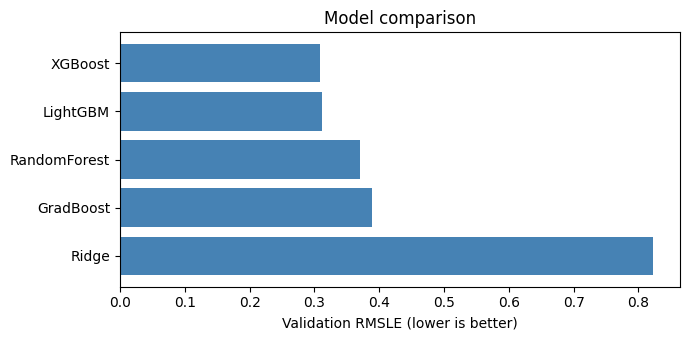

In [8]:
# Cell 7: bar chart of the model comparison (good for the slides)
plt.figure(figsize=(7, 3.5))
plt.barh(results['model'][::-1], results['RMSLE'][::-1], color='steelblue')
plt.xlabel('Validation RMSLE (lower is better)')
plt.title('Model comparison')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'model_comparison.png', dpi=150)
plt.show()

In [9]:
# Cell 8: hyperparameter tuning on the best non-linear model.
# RandomizedSearchCV tries random settings; TimeSeriesSplit keeps the folds in time order.
best_name = results[results['model'] != 'Ridge'].iloc[0]['model']
print('Tuning:', best_name)

param_grids = {
    'RandomForest': {'model__n_estimators': [200, 400, 600], 'model__max_depth': [8, 12, 16, None],
                     'model__min_samples_leaf': [1, 2, 4], 'model__max_features': [0.5, 0.7, 1.0]},
    'GradBoost':    {'model__n_estimators': [200, 400, 600], 'model__learning_rate': [0.03, 0.05, 0.1],
                     'model__max_depth': [3, 4, 5, 6], 'model__subsample': [0.7, 0.85, 1.0]},
    'XGBoost':      {'model__n_estimators': [300, 500, 800], 'model__learning_rate': [0.02, 0.05, 0.1],
                     'model__max_depth': [4, 6, 8], 'model__subsample': [0.7, 0.85, 1.0],
                     'model__colsample_bytree': [0.7, 0.85, 1.0], 'model__min_child_weight': [1, 3, 5]},
    'LightGBM':     {'model__n_estimators': [300, 500, 800], 'model__learning_rate': [0.02, 0.05, 0.1],
                     'model__num_leaves': [31, 63, 127], 'model__min_child_samples': [10, 20, 40],
                     'model__colsample_bytree': [0.7, 0.85, 1.0]},
}

search = RandomizedSearchCV(
    make_pipeline(clone(models[best_name])),
    param_distributions=param_grids[best_name],
    n_iter=15,                                   # 15 random combinations
    scoring='neg_root_mean_squared_error',       # on log target this equals RMSLE
    cv=TimeSeriesSplit(n_splits=3),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_tr, y_tr)
print('best settings:', search.best_params_)
print('cross-validated RMSLE:', round(-search.best_score_, 4))

Tuning: XGBoost
Fitting 3 folds for each of 15 candidates, totalling 45 fits
best settings: {'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.85}
cross-validated RMSLE: 0.4322


In [10]:
# Cell 9: is the tuned model actually better on the validation set? Keep whichever wins.
tuned_pipe = search.best_estimator_
tuned_row = evaluate(f'{best_name} (tuned)', tuned_pipe, X_va, y_va)
print('untuned:', results[results['model'] == best_name].iloc[0].to_dict())
print('tuned  :', tuned_row)

untuned_rmsle = results[results['model'] == best_name].iloc[0]['RMSLE']
if tuned_row['RMSLE'] <= untuned_rmsle:
    final_name, final_pipe = tuned_row['model'], tuned_pipe
else:
    final_name, final_pipe = best_name, fitted[best_name]
print('FINAL MODEL:', final_name)

# save the full comparison table (goes into the write-up)
results_final = pd.concat([results, pd.DataFrame([tuned_row])]).sort_values('RMSLE').reset_index(drop=True)
results_final.to_csv(RESULTS_PATH, index=False)
results_final

untuned: {'model': 'XGBoost', 'RMSLE': 0.3079, 'RMSE': 60.51, 'R2': 0.9227}
tuned  : {'model': 'XGBoost (tuned)', 'RMSLE': 0.3276, 'RMSE': 71.29, 'R2': 0.8927}
FINAL MODEL: XGBoost


,model,RMSLE,RMSE,R2
0,XGBoost,0.3079,60.51,0.9227
1,LightGBM,0.3121,61.62,0.9198
2,XGBoost (tuned),0.3276,71.29,0.8927
3,RandomForest,0.3701,80.46,0.8633
4,GradBoost,0.3885,95.11,0.8090
5,Ridge,0.8230,177.20,0.3369


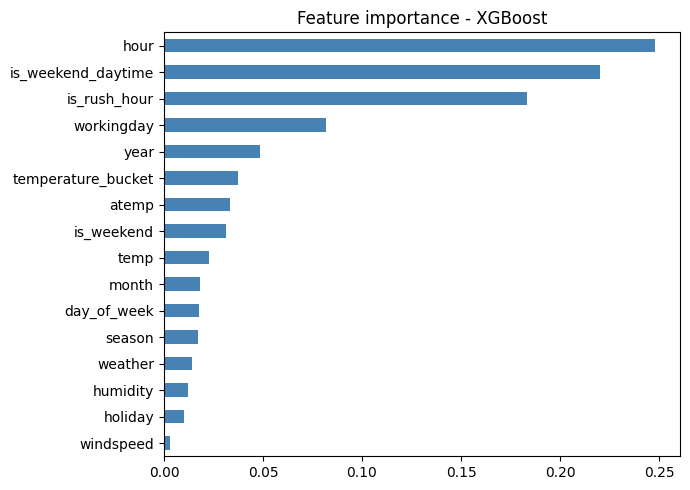

hour                  0.248179
is_weekend_daytime    0.220339
is_rush_hour          0.183237
workingday            0.082033
year                  0.048660
dtype: float32


In [11]:
# Cell 10: which features matter most to the final model?
model = final_pipe.named_steps['model']
names = final_pipe.named_steps['select'].get_feature_names_out()

if hasattr(model, 'feature_importances_'):
    imp = pd.Series(model.feature_importances_, index=names).sort_values()
    plt.figure(figsize=(7, 5))
    imp.plot(kind='barh', color='steelblue')
    plt.title(f'Feature importance - {final_name}')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'feature_importance.png', dpi=150)
    plt.show()
    print(imp.sort_values(ascending=False).head(5))

final validation scores: {'RMSLE': 0.3079, 'RMSE': 60.51, 'R2': 0.9227}


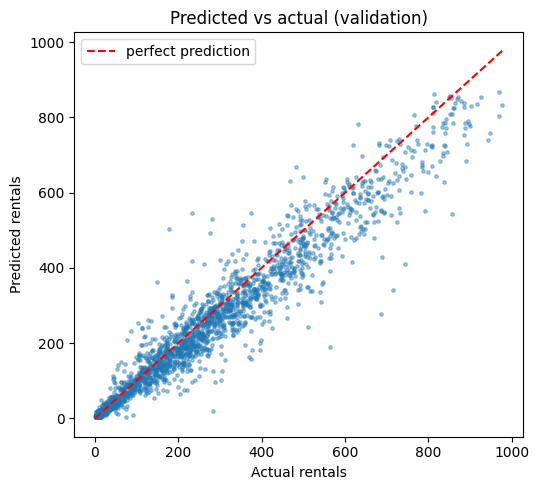

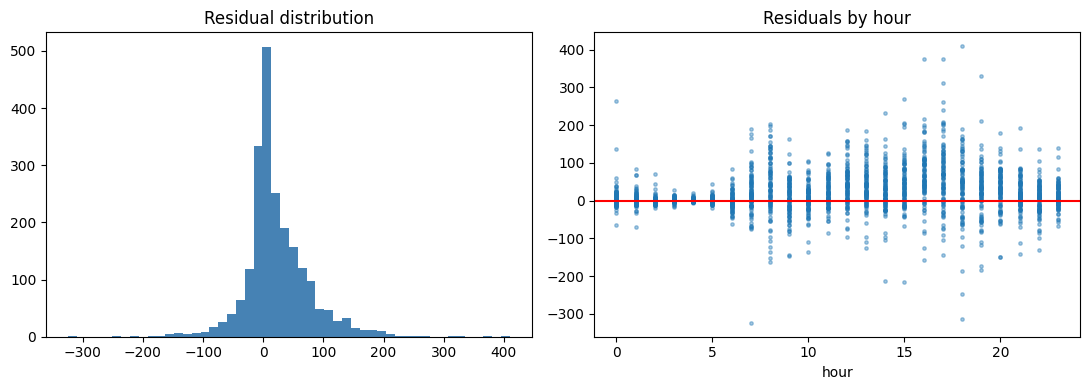

In [12]:
# Cell 11: how close are the predictions on the validation set? (real counts, not logs)
pred_log = final_pipe.predict(X_va)
pred = to_counts(pred_log)
actual = np.expm1(y_va.values)
print('final validation scores:', score(y_va, pred_log))

# predicted vs actual
plt.figure(figsize=(5.5, 5))
plt.scatter(actual, pred, s=6, alpha=0.4)
lim = max(actual.max(), pred.max())
plt.plot([0, lim], [0, lim], 'r--', label='perfect prediction')
plt.xlabel('Actual rentals'); plt.ylabel('Predicted rentals')
plt.title('Predicted vs actual (validation)'); plt.legend()
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'pred_vs_actual.png', dpi=150); plt.show()

# residuals = actual - predicted
resid = actual - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(resid, bins=50, color='steelblue'); ax[0].set_title('Residual distribution')
ax[1].scatter(X_va['hour'], resid, s=6, alpha=0.4); ax[1].axhline(0, color='r')
ax[1].set_title('Residuals by hour'); ax[1].set_xlabel('hour')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'residuals.png', dpi=150); plt.show()

In [13]:
# Cell 12: for the final demo model, retrain on ALL the data (train + validation),
# because more recent data helps predict the future. The scores above stay valid:
# they came from the model that didn't see the validation rows.
final_full = clone(final_pipe).fit(X, y)
joblib.dump(final_full, MODEL_PATH, compress=3)
print('saved to', MODEL_PATH)
print('size (MB):', round(MODEL_PATH.stat().st_size / 1e6, 2))

saved to /content/drive/MyDrive/ml_mini_project/ML-Bike-Rental-Demand-Forecasting/models/best_model.joblib
size (MB): 0.68


In [14]:
# Cell 13: reload the model and predict on Naija's test file, the same steps the demo will use
loaded = joblib.load(MODEL_PATH)
X_test, warns = make_prediction_features(load_test_data())
test_pred = to_counts(loaded.predict(X_test))
print('X_test shape:', X_test.shape)
print('predictions :', test_pred.shape, '| min', test_pred.min().round(1),
      '| max', test_pred.max().round(1), '| mean', test_pred.mean().round(1))

X_test shape: (6493, 17)
predictions : (6493,) | min 0.8 | max 940.8 | mean 185.3


In [15]:
# Cell 14: write these versions into requirements.txt so VS Code matches Colab
import sklearn, xgboost, lightgbm, pandas, numpy
for lib in [sklearn, xgboost, lightgbm, pandas, numpy]:
    print(lib.__name__, lib.__version__)

sklearn 1.6.1
xgboost 3.4.1
lightgbm 4.6.0
pandas 2.2.3
numpy 2.1.3
